222 labels, 73 distinct, 60 trip events, 2025-05-28 to 2026-06-29

labels per system type (rows / distinct events):
                     rows  events
system                           
BPM (beam position)   107      20
HBL cavity             40       4
MBL cavity             27       4
MEBT buncher           18      18
BCM (beam current)     10       8
Dump-line imaging       9       9
DTL tank                8       5
RFQ                     2       2
Spoke cavity            1       1

events with many labels (likely one trip seen by many systems):
                                 event_ts  n_labels                                                systems
event_id                                                                                                  
16095417116 2026-06-07 06:58:20.716942051        10                               BPM (beam position), RFQ
16121485108 2026-06-28 20:10:49.067010260        11                                    BPM (beam position)
16121491464 2026-

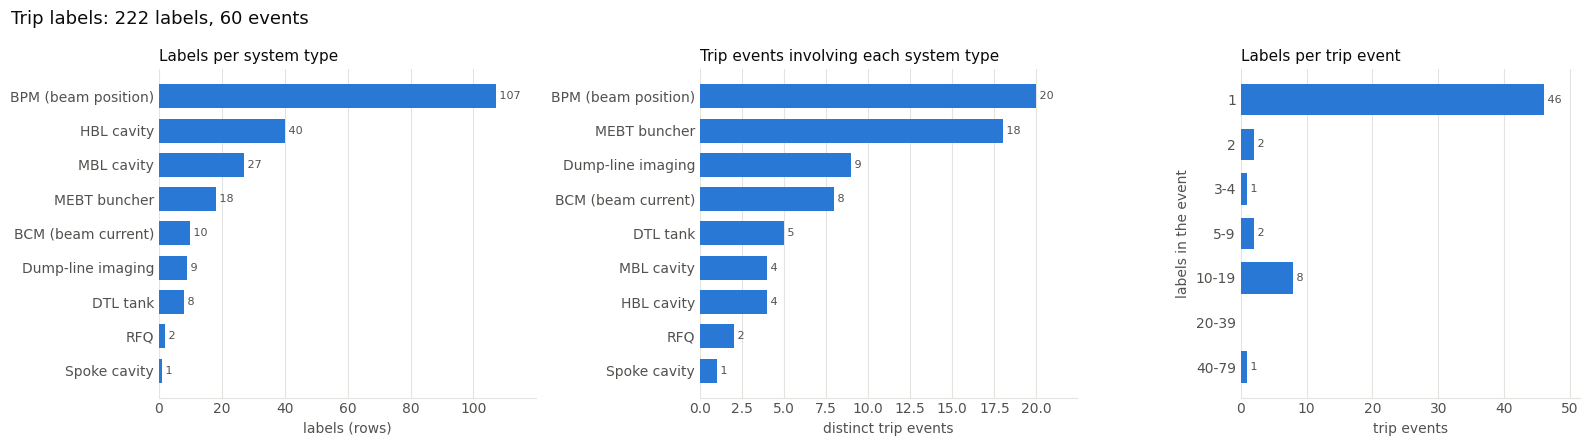

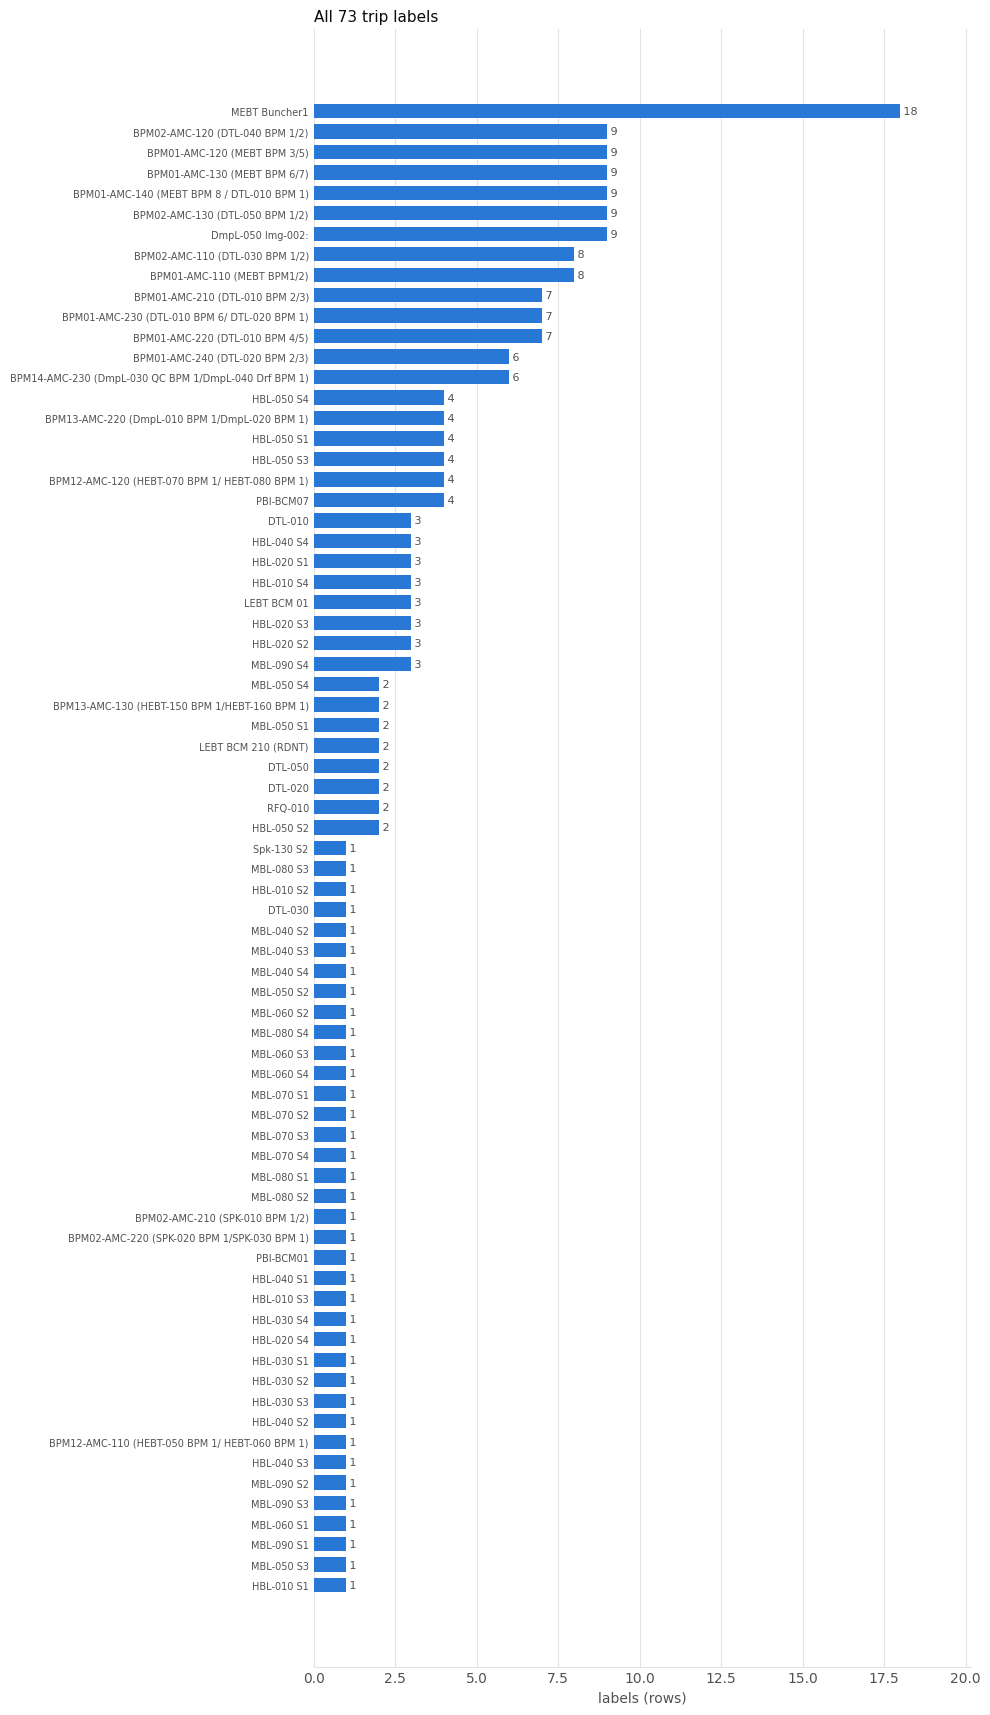

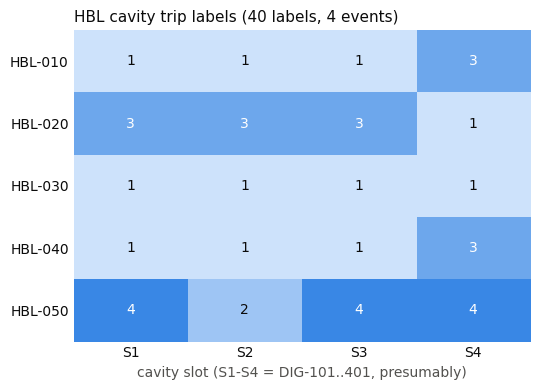

In [2]:
"""
plot_trip_labels.py
Histograms of the trip labels in trip_labels.parquet.

The file has one row per (trip event, tripped system):
    event_id          the trip event (several rows share it when several systems tripped)
    event_ts          when it happened
    trip_description  which system tripped, e.g. "HBL-050 S1", "MEBT Buncher1",
                      "BPM01-AMC-110 (MEBT BPM1/2)", "PBI-BCM07", "DmpL-050 Img-002:"

Figures:
  1. labels per system type, as rows and as distinct events, + labels per event
  2. every individual label, sorted by count
  3. HBL cavities: trips per cryomodule x cavity slot (S1..S4)

Run:  python plot_trip_labels.py
Needs: pandas, matplotlib, pyarrow
"""

import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================ SETTINGS ============================
LABELS_FILE = "trip_labels.parquet"
TOP_N = None            # figure 2: show only the N most frequent labels (None = all)
SAVE_FIGURES = True     # also write the figures as PNG files
# =================================================================

BLUE = "#2a78d6"                     # single-series bars
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ_BLUES = ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95"]


def system_type(label):
    """Group the free-text label into a system type."""
    rules = [
        (r"^HBL-\d+ S\d", "HBL cavity"),
        (r"^MBL-\d+ S\d", "MBL cavity"),
        (r"^Spk-\d+ S\d", "Spoke cavity"),
        (r"^BPM", "BPM (beam position)"),
        (r"BCM", "BCM (beam current)"),
        (r"^DTL", "DTL tank"),
        (r"^RFQ", "RFQ"),
        (r"Buncher", "MEBT buncher"),
        (r"Img", "Dump-line imaging"),
    ]
    for pattern, name in rules:
        if re.search(pattern, label):
            return name
    return "Other"


def style(ax, xlabel):
    ax.set_xlabel(xlabel, color=INK_2)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_2, length=0)


def hbars(ax, counts, xlabel, title):
    """Horizontal bars, largest on top, value written at the end of each bar."""
    counts = counts.sort_values()
    y = np.arange(len(counts))
    ax.barh(y, counts.values, color=BLUE, height=0.7)
    ax.set_yticks(y, counts.index, color=INK)
    for yi, v in zip(y, counts.values):
        ax.text(v, yi, f" {v}", va="center", fontsize=8, color=INK_2)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    style(ax, xlabel)
    ax.set_xlim(0, counts.max() * 1.12)


def main():
    df = pd.read_parquet(LABELS_FILE)
    df["event_ts"] = pd.to_datetime(df["event_ts"])
    df["system"] = df["trip_description"].map(system_type)

    n_events = df["event_id"].nunique()
    per_event = df.groupby("event_id").agg(
        event_ts=("event_ts", "first"), n_labels=("trip_description", "size"),
        systems=("system", lambda s: ", ".join(sorted(set(s))))).sort_values("event_ts")
    print(f"{len(df)} labels, {df['trip_description'].nunique()} distinct, {n_events} trip events, "
          f"{df['event_ts'].min():%Y-%m-%d} to {df['event_ts'].max():%Y-%m-%d}")
    print("\nlabels per system type (rows / distinct events):")
    print(pd.DataFrame({"rows": df["system"].value_counts(),
                        "events": df.groupby("system")["event_id"].nunique()})
            .sort_values("rows", ascending=False).to_string())
    print("\nevents with many labels (likely one trip seen by many systems):")
    print(per_event[per_event["n_labels"] >= 10].to_string())
    per_event.to_csv("trip_events.csv")

    # ---------------------------------------------------- figure 1: by system type
    fig1, axes = plt.subplots(1, 3, figsize=(16, 4.5),
                              gridspec_kw={"width_ratios": [1, 1, 0.9]})
    hbars(axes[0], df["system"].value_counts(), "labels (rows)",
          "Labels per system type")
    hbars(axes[1], df.groupby("system")["event_id"].nunique(), "distinct trip events",
          "Trip events involving each system type")

    # how many systems tripped together: 1 label = a single system, many = a global trip
    ax = axes[2]
    bins = [1, 2, 3, 5, 10, 20, 40, 80]
    hist, _ = np.histogram(per_event["n_labels"], bins=bins)
    names = [f"{a}" if b - a == 1 else f"{a}-{b - 1}" for a, b in zip(bins[:-1], bins[1:])]
    y = np.arange(len(names))
    ax.barh(y, hist, color=BLUE, height=0.7)
    ax.set_yticks(y, names, color=INK)
    ax.invert_yaxis()
    for yi, v in zip(y, hist):
        if v:
            ax.text(v, yi, f" {v}", va="center", fontsize=8, color=INK_2)
    ax.set_ylabel("labels in the event", color=INK_2)
    ax.set_title("Labels per trip event", loc="left", fontsize=11, color=INK)
    style(ax, "trip events")
    ax.set_xlim(0, max(hist) * 1.12)
    fig1.suptitle(f"Trip labels: {len(df)} labels, {n_events} events", x=0.01, ha="left",
                  fontsize=13, color=INK)
    fig1.tight_layout()

    # ---------------------------------------------------- figure 2: every label
    counts = df["trip_description"].value_counts()
    if TOP_N:
        counts = counts.head(TOP_N)
    fig2, ax = plt.subplots(figsize=(10, 0.22 * len(counts) + 1.2))
    hbars(ax, counts, "labels (rows)",
          f"{'Top ' + str(TOP_N) if TOP_N else 'All'} {len(counts)} trip labels")
    ax.tick_params(axis="y", labelsize=7)
    fig2.tight_layout()

    # ---------------------------------------------------- figure 3: HBL cavities
    hbl = df["trip_description"].str.extract(r"^HBL-(?P<cm>\d+) S(?P<slot>\d)").dropna()
    figs = [("trip_labels_by_system.png", fig1), ("trip_labels_all.png", fig2)]
    if len(hbl):
        grid = (pd.crosstab(hbl["cm"], hbl["slot"])
                  .reindex(index=["010", "020", "030", "040", "050"],
                           columns=["1", "2", "3", "4"], fill_value=0))
        fig3, ax = plt.subplots(figsize=(5.5, 4))
        cmap = plt.matplotlib.colors.ListedColormap(SEQ_BLUES[:grid.values.max() + 1])
        ax.imshow(grid.values, cmap=cmap, vmin=-0.5, vmax=grid.values.max() + 0.5,
                  aspect="auto")
        for (r, c), v in np.ndenumerate(grid.values):
            ax.text(c, r, str(v), ha="center", va="center", fontsize=10,
                    color="white" if v >= 3 else INK)
        ax.set_xticks(range(4), [f"S{s}" for s in grid.columns], color=INK)
        ax.set_yticks(range(len(grid)), [f"HBL-{cm}" for cm in grid.index], color=INK)
        ax.set_xlabel("cavity slot (S1-S4 = DIG-101..401, presumably)", color=INK_2)
        ax.set_title(f"HBL cavity trip labels ({len(hbl)} labels, "
                     f"{df.loc[hbl.index, 'event_id'].nunique()} events)",
                     loc="left", fontsize=11, color=INK)
        ax.tick_params(length=0)
        for side in ax.spines.values():
            side.set_visible(False)
        fig3.tight_layout()
        figs.append(("trip_labels_hbl.png", fig3))

    if SAVE_FIGURES:
        for name, f in figs:
            f.savefig(name, dpi=130, facecolor="#fcfcfb")
        print("\nsaved:", ", ".join(n for n, _ in figs), "and trip_events.csv")
    plt.show()


if __name__ == "__main__":
    main()